# Mini Project Set 07 – Retail Sales Forecasting and Store/Item Grouping
**Dataset:** Corporación Favorita – Store Sales Time Series Forecasting (Kaggle)

**Steps:** load & clean → features → regression → classification (KNN, NB) → SVM kernels → Decision Tree / Random Forest → K-Means → conclusion

## Cell 1 – Imports

In [27]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score)

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully")

Libraries imported successfully


## Task 1 – Load and inspect data
**Cell 2 – Set the folder path** (the folder where you extracted the zip; it must directly contain `train.csv`)

In [28]:
DATA_DIR = r"C:\Users\YASH SONI\Desktop\store-sales-time-series-forecasting"
print(os.listdir(DATA_DIR))

['holidays_events.csv', 'oil.csv', 'Retail_Sales_Forecasting_Mini_Project_07.ipynb', 'stores.csv', 'train.csv']


**Cell 3 – Load the files (dates are parsed here)**

In [29]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), parse_dates=["date"])
stores = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
oil = pd.read_csv(os.path.join(DATA_DIR, "oil.csv"), parse_dates=["date"])
hol = pd.read_csv(os.path.join(DATA_DIR, "holidays_events.csv"), parse_dates=["date"])

print("train   :", train.shape)
print("stores  :", stores.shape)
print("oil     :", oil.shape)
print("holidays:", hol.shape)
display(train.head())
display(stores.head())

train   : (3000888, 6)
stores  : (54, 5)
oil     : (1218, 2)
holidays: (350, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


**Cell 4 – Missing values, duplicates, dates**

In [30]:
print("Missing values in train:\n", train.isnull().sum(), "\n")
print("Missing values in stores:\n", stores.isnull().sum(), "\n")
print("Missing values in oil:\n", oil.isnull().sum(), "\n")
print("Duplicate rows in train :", train.duplicated().sum())
print("Duplicate (date,store,family) keys:", train.duplicated(subset=["date", "store_nbr", "family"]).sum())
print("Negative sales rows     :", (train["sales"] < 0).sum())
print("Date range:", train["date"].min().date(), "to", train["date"].max().date())

all_days = pd.date_range(train["date"].min(), train["date"].max())
missing_days = all_days.difference(train["date"].unique())
print("Calendar days missing from train (stores closed, e.g. 25 Dec):", list(missing_days.strftime("%Y-%m-%d")))

Missing values in train:
 id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64 

Missing values in stores:
 store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64 

Missing values in oil:
 date           0
dcoilwtico    43
dtype: int64 

Duplicate rows in train : 0
Duplicate (date,store,family) keys: 0
Negative sales rows     : 0
Date range: 2013-01-01 to 2017-08-15
Calendar days missing from train (stores closed, e.g. 25 Dec): ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


**Cell 5 – Clean inconsistent labels, fill oil gaps, build holiday flag, merge tables**

In [31]:
# --- consistent text labels ---
train["family"] = train["family"].astype(str).str.strip().str.upper()
stores["city"] = stores["city"].astype(str).str.strip().str.title()
stores["state"] = stores["state"].astype(str).str.strip().str.title()
stores["type"] = stores["type"].astype(str).str.strip().str.upper()
stores = stores.rename(columns={"type": "store_type"})
print("Product families:", train["family"].nunique(), "| Cities:", stores["city"].nunique(),
      "| States:", stores["state"].nunique(), "| Store types:", sorted(stores["store_type"].unique()))

# --- oil price: fill missing days (interpolate, then forward/back fill the edges) ---
oil = oil.drop_duplicates(subset="date").set_index("date")
oil = oil.reindex(pd.date_range(train["date"].min(), train["date"].max())).rename_axis("date")
oil["dcoilwtico"] = oil["dcoilwtico"].interpolate().ffill().bfill()
oil = oil.reset_index()

# --- national holidays flag (ignore transferred holidays and work days) ---
hol["transferred"] = hol["transferred"].astype(str).str.lower() == "true"
hol_ok = hol[(hol["locale"] == "National") & (hol["type"] != "Work Day") & (~hol["transferred"])]
holiday_days = set(hol_ok["date"])

# --- merge into one table ---
full = (train.drop(columns=["id"], errors="ignore")
             .merge(stores, on="store_nbr", how="left")
             .merge(oil, on="date", how="left"))
full["is_holiday"] = full["date"].isin(holiday_days).astype(int)
print("Merged table:", full.shape)
print("Missing values after cleaning:", int(full.isnull().sum().sum()))
display(full.head())

Product families: 33 | Cities: 22 | States: 16 | Store types: ['A', 'B', 'C', 'D', 'E']
Merged table: (3000888, 11)
Missing values after cleaning: 0


,date,store_nbr,family,sales,onpromotion,city,state,store_type,cluster,dcoilwtico,is_holiday
0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1
1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1
2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1
3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1
4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1


## Task 2 – Feature engineering, encoding, scaling
The full data has about 3 million rows. For the supervised models we use **12 random stores** and the period **Aug 2016 – Aug 2017** so that SVM/KNN run in reasonable time. K-Means (Task 7) uses the full data.

**Cell 6 – Select subset and create date + lag features**

In [32]:
rng = np.random.RandomState(RANDOM_STATE)
chosen_stores = rng.choice(full["store_nbr"].unique(), size=12, replace=False)

df = full[(full["date"] >= "2016-08-01") & (full["store_nbr"].isin(chosen_stores))].copy()
df = df.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)

# date features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["is_payday"] = ((df["day"] == 15) | df["date"].dt.is_month_end).astype(int)

# lag features (past sales of the same store+family, known one week ahead -> no leakage)
grp = df.groupby(["store_nbr", "family"])["sales"]
df["lag_7"] = grp.shift(7)
df["lag_14"] = grp.shift(14)
df["roll_mean_7"] = grp.transform(lambda s: s.shift(7).rolling(7).mean())
df = df.dropna(subset=["lag_7", "lag_14", "roll_mean_7"]).reset_index(drop=True)
print("Modelling data:", df.shape)
display(df.head())

Modelling data: (144540, 21)


,date,store_nbr,family,sales,onpromotion,city,state,store_type,cluster,dcoilwtico,...,year,month,day,dayofweek,weekofyear,is_weekend,is_payday,lag_7,lag_14,roll_mean_7
0,2016-08-15,5,AUTOMOTIVE,7.0,0,Santo Domingo,Santo Domingo De Los Tsachilas,D,4,45.72,...,2016,8,15,0,33,0,1,14.0,9.0,6.571429
1,2016-08-16,5,AUTOMOTIVE,11.0,0,Santo Domingo,Santo Domingo De Los Tsachilas,D,4,46.57,...,2016,8,16,1,33,0,0,5.0,5.0,6.571429
2,2016-08-17,5,AUTOMOTIVE,13.0,0,Santo Domingo,Santo Domingo De Los Tsachilas,D,4,46.81,...,2016,8,17,2,33,0,0,7.0,3.0,7.142857
3,2016-08-18,5,AUTOMOTIVE,7.0,0,Santo Domingo,Santo Domingo De Los Tsachilas,D,4,48.20,...,2016,8,18,3,33,0,0,4.0,2.0,7.428571
4,2016-08-19,5,AUTOMOTIVE,5.0,0,Santo Domingo,Santo Domingo De Los Tsachilas,D,4,48.48,...,2016,8,19,4,33,0,0,8.0,8.0,7.428571


**Cell 7 – Encode categorical columns**

In [33]:
for col in ["family", "city", "state"]:
    df[col + "_code"] = LabelEncoder().fit_transform(df[col])
df = pd.get_dummies(df, columns=["store_type"], prefix="type", dtype=int)

feature_cols = (["store_nbr", "family_code", "city_code", "state_code", "cluster",
                 "onpromotion", "dcoilwtico", "is_holiday",
                 "year", "month", "day", "dayofweek", "weekofyear", "is_weekend", "is_payday",
                 "lag_7", "lag_14", "roll_mean_7"]
                + [c for c in df.columns if c.startswith("type_")])
print(len(feature_cols), "features:", feature_cols)

21 features: ['store_nbr', 'family_code', 'city_code', 'state_code', 'cluster', 'onpromotion', 'dcoilwtico', 'is_holiday', 'year', 'month', 'day', 'dayofweek', 'weekofyear', 'is_weekend', 'is_payday', 'lag_7', 'lag_14', 'roll_mean_7', 'type_B', 'type_C', 'type_D']


**Cell 8 – Chronological (time-aware) split and scaling**
The first 80% of the dates are used for training and the last 20% for testing. No shuffling.

In [34]:
unique_dates = np.sort(df["date"].unique())
cutoff = unique_dates[int(len(unique_dates) * 0.8)]
train_df = df[df["date"] < cutoff].reset_index(drop=True)
test_df = df[df["date"] >= cutoff].reset_index(drop=True)
print("Train:", train_df["date"].min().date(), "->", train_df["date"].max().date(), "| rows:", len(train_df))
print("Test :", test_df["date"].min().date(), "->", test_df["date"].max().date(), "| rows:", len(test_df))

X_train, X_test = train_df[feature_cols], test_df[feature_cols]
y_train, y_test = train_df["sales"], test_df["sales"]

scaler = StandardScaler().fit(X_train)          # fit on TRAIN only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print("Scaling done")

Train: 2016-08-15 -> 2017-06-03 | rows: 115632
Test : 2017-06-04 -> 2017-08-15 | rows: 28908
Scaling done


## Task 3 – Regression: predict sales quantity
**Cell 9 – Linear Regression and Random Forest Regressor**

In [35]:
def reg_metrics(name, y_true, y_pred):
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

lin = LinearRegression().fit(X_train_s, y_train)
pred_lin = np.clip(lin.predict(X_test_s), 0, None)

rf_reg = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=5,
                               n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
pred_rf = rf_reg.predict(X_test)

reg_table = pd.DataFrame([reg_metrics("Linear Regression", y_test, pred_lin),
                          reg_metrics("Random Forest Regressor", y_test, pred_rf)]).round(3)
display(reg_table)

,Model,MAE,RMSE,R2
0,Linear Regression,86.706,285.143,0.917
1,Random Forest Regressor,60.259,249.244,0.937


**Cell 10 – Plot actual vs predicted (chronological)**

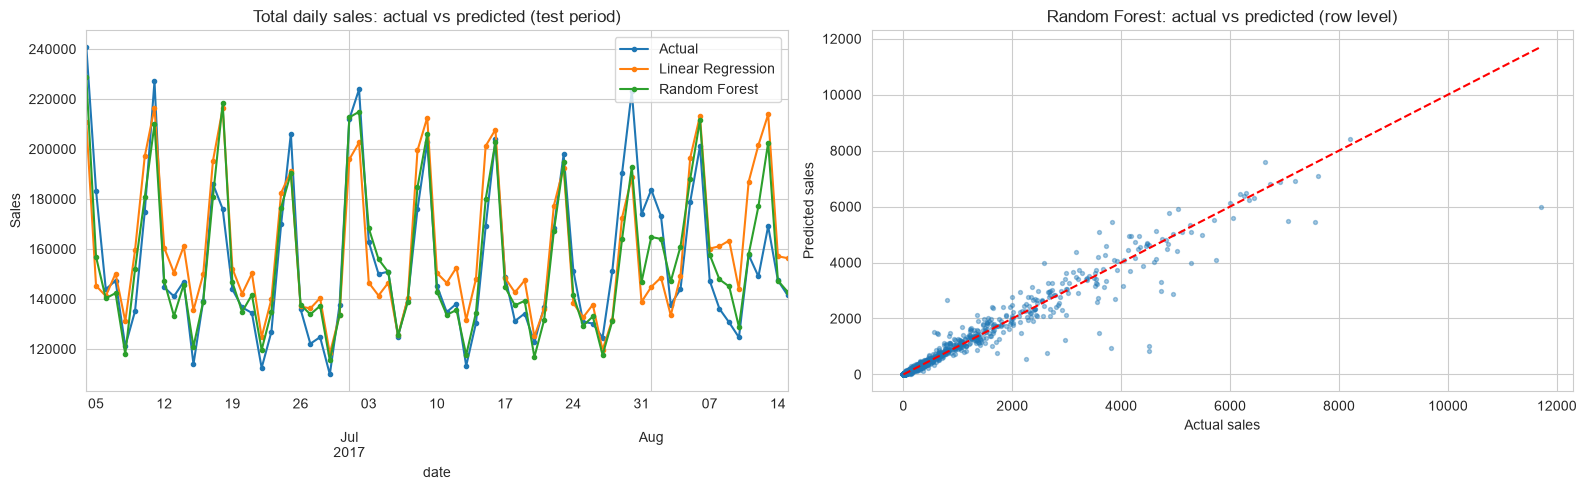

In [36]:
res = pd.DataFrame({"date": test_df["date"], "Actual": y_test,
                    "Linear Regression": pred_lin, "Random Forest": pred_rf})
daily = res.groupby("date").sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
daily.plot(ax=axes[0], marker="o", ms=3)
axes[0].set_title("Total daily sales: actual vs predicted (test period)")
axes[0].set_ylabel("Sales")

samp = res.sample(min(3000, len(res)), random_state=RANDOM_STATE)
axes[1].scatter(samp["Actual"], samp["Random Forest"], s=8, alpha=0.4)
lim = max(samp["Actual"].max(), samp["Random Forest"].max())
axes[1].plot([0, lim], [0, lim], "r--")
axes[1].set_xlabel("Actual sales"); axes[1].set_ylabel("Predicted sales")
axes[1].set_title("Random Forest: actual vs predicted (row level)")
plt.tight_layout(); plt.show()

## Task 4 – Low / Medium / High classes, then KNN and Naive Bayes
**Cell 11 – Define class thresholds (from TRAIN data: 33rd and 66th percentile) and sample for speed**

In [37]:
t1, t2 = np.quantile(y_train, [0.33, 0.66])
print(f"Thresholds -> Low: sales <= {t1:.1f} | Medium: {t1:.1f} < sales <= {t2:.1f} | High: sales > {t2:.1f}")

def to_class(s):
    return pd.cut(s, bins=[-np.inf, t1, t2, np.inf], labels=["Low", "Medium", "High"]).astype(str)

ytr_all, yte_all = to_class(y_train), to_class(y_test)
print(ytr_all.value_counts(), "\n")

# random samples (positions) so that KNN / SVM run quickly; same samples for ALL classifiers
rs = np.random.RandomState(RANDOM_STATE)
tr_pos = rs.choice(len(train_df), size=min(8000, len(train_df)), replace=False)
te_pos = rs.choice(len(test_df), size=min(4000, len(test_df)), replace=False)

Xtr_s, Xte_s = X_train_s[tr_pos], X_test_s[te_pos]          # scaled (KNN, NB, SVM)
Xtr_r, Xte_r = X_train.values[tr_pos], X_test.values[te_pos]  # raw (trees)
ytr_c, yte_c = ytr_all.values[tr_pos], yte_all.values[te_pos]
print("Classification samples:", Xtr_s.shape, Xte_s.shape)

Thresholds -> Low: sales <= 6.0 | Medium: 6.0 < sales <= 132.8 | High: sales > 132.8
sales
Low       40250
High      39315
Medium    36067
Name: count, dtype: int64 

Classification samples: (8000, 21) (4000, 21)


**Cell 12 – Evaluation helpers**

In [38]:
labels_order = ["Low", "Medium", "High"]
cls_results, cls_preds = [], {}

def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    cls_preds[name] = pred
    cls_results.append({"Model": name,
                        "Accuracy": accuracy_score(yte, pred),
                        "Precision": precision_score(yte, pred, average="weighted", zero_division=0),
                        "Recall": recall_score(yte, pred, average="weighted", zero_division=0),
                        "F1-score": f1_score(yte, pred, average="weighted", zero_division=0)})
    return pred

def plot_cm(name, yte, pred, ax=None):
    cm = confusion_matrix(yte, pred, labels=labels_order)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order,
                yticklabels=labels_order, ax=ax, cbar=False)
    (ax.set_title(name) if ax is not None else plt.title(name))

**Cell 13 – KNN and Naive Bayes**

,Model,Accuracy,Precision,Recall,F1-score
0,KNN (k=5),0.5538,0.5584,0.5538,0.5555
1,Naive Bayes,0.7382,0.7840,0.7382,0.7249


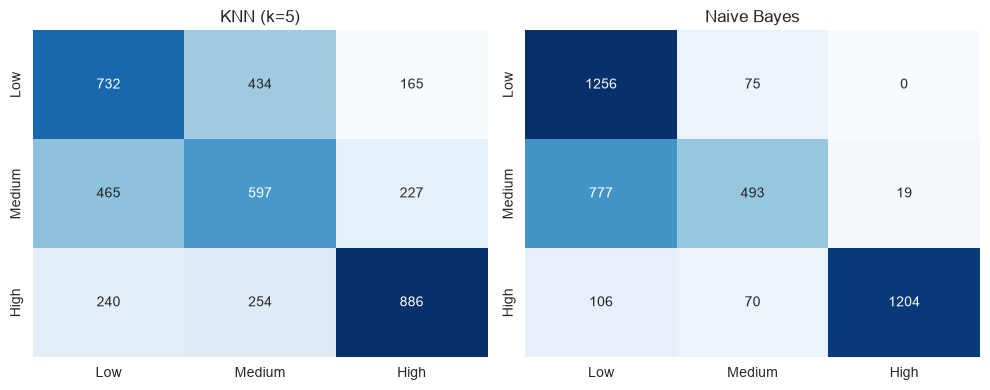

              precision    recall  f1-score   support

         Low       0.51      0.55      0.53      1331
      Medium       0.46      0.46      0.46      1289
        High       0.69      0.64      0.67      1380

    accuracy                           0.55      4000
   macro avg       0.56      0.55      0.55      4000
weighted avg       0.56      0.55      0.56      4000



In [39]:
evaluate("KNN (k=5)", KNeighborsClassifier(n_neighbors=5), Xtr_s, ytr_c, Xte_s, yte_c)
evaluate("Naive Bayes", GaussianNB(), Xtr_s, ytr_c, Xte_s, yte_c)

display(pd.DataFrame(cls_results).round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nm in zip(axes, ["KNN (k=5)", "Naive Bayes"]):
    plot_cm(nm, yte_c, cls_preds[nm], ax)
plt.tight_layout(); plt.show()
print(classification_report(yte_c, cls_preds["KNN (k=5)"], labels=labels_order, zero_division=0))

## Task 5 – SVM: Linear, Polynomial, RBF
**Cell 14 – Train three SVMs (may take 1–3 minutes)**

,Model,Accuracy,Precision,Recall,F1-score
0,SVM linear,0.8352,0.8610,0.8352,0.8265
1,SVM poly,0.6948,0.7112,0.6948,0.7010
2,SVM rbf,0.7442,0.7487,0.7442,0.7434


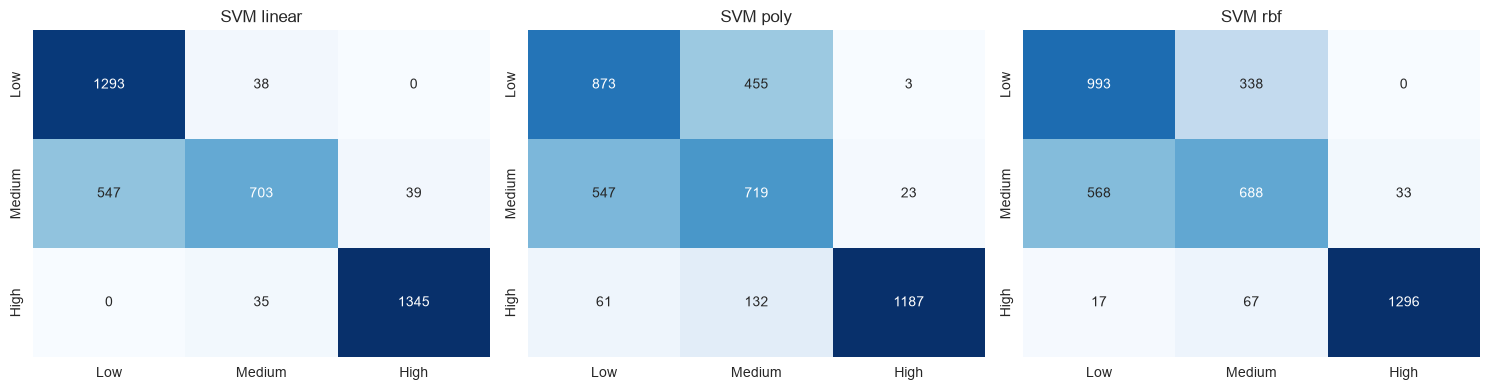

In [40]:
for kern in ["linear", "poly", "rbf"]:
    evaluate(f"SVM {kern}", SVC(kernel=kern, C=1.0, gamma="scale", degree=3), Xtr_s, ytr_c, Xte_s, yte_c)

svm_table = pd.DataFrame([r for r in cls_results if r["Model"].startswith("SVM")]).round(4)
display(svm_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nm in zip(axes, ["SVM linear", "SVM poly", "SVM rbf"]):
    plot_cm(nm, yte_c, cls_preds[nm], ax)
plt.tight_layout(); plt.show()

## Task 6 – Entropy-based decision tree and Random Forest
**Cell 15 – ID3-style tree (criterion = entropy)**

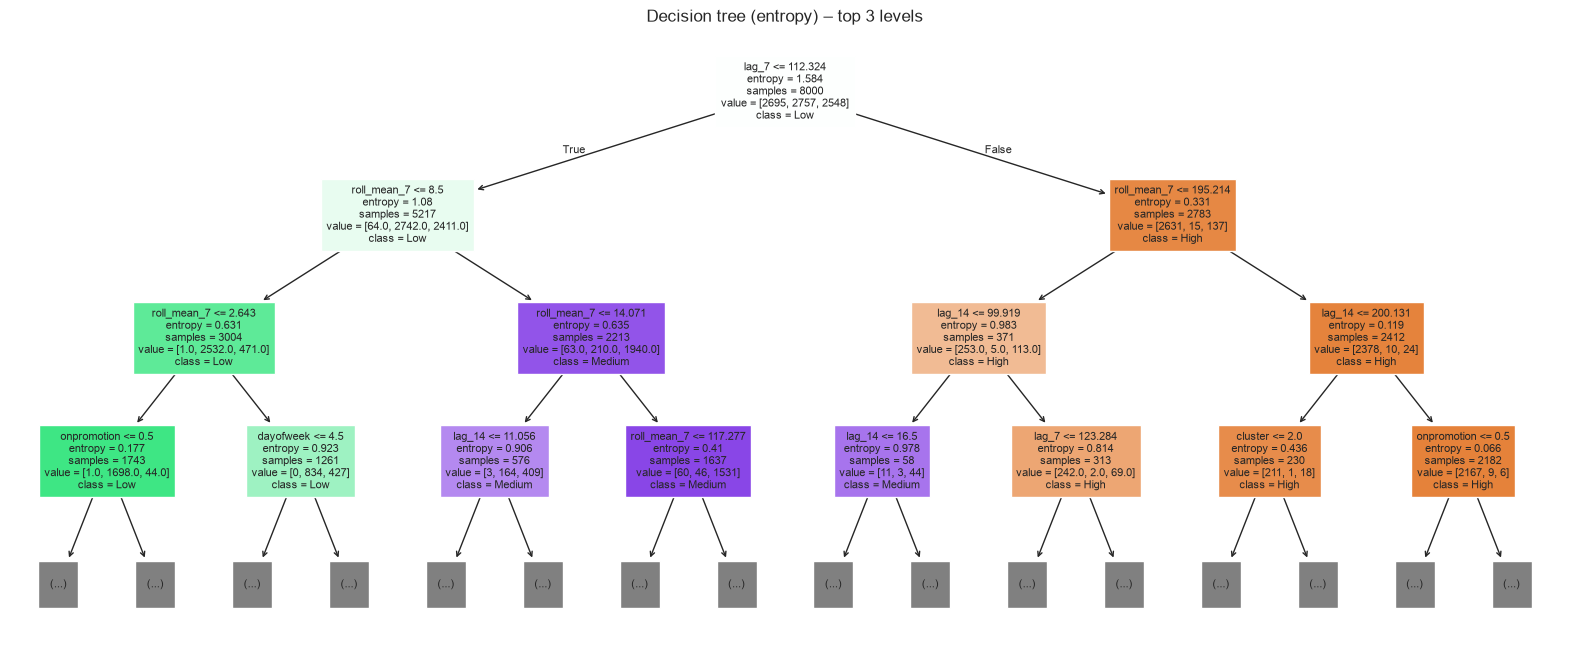

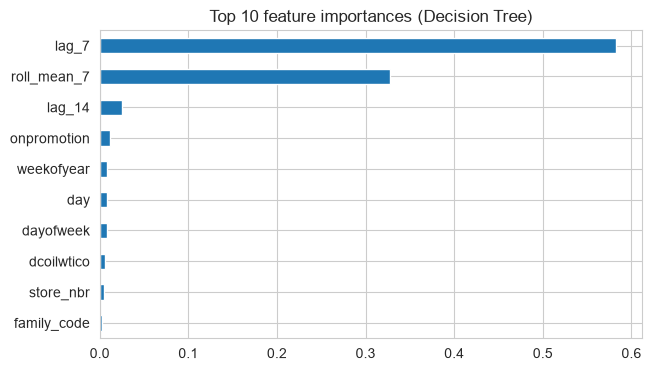

In [41]:
dt = DecisionTreeClassifier(criterion="entropy", max_depth=8, random_state=RANDOM_STATE)
evaluate("Decision Tree (entropy)", dt, Xtr_r, ytr_c, Xte_r, yte_c)

plt.figure(figsize=(20, 8))
plot_tree(dt, feature_names=feature_cols, class_names=dt.classes_, filled=True, max_depth=3, fontsize=8)
plt.title("Decision tree (entropy) – top 3 levels")
plt.show()

imp = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
imp.plot(kind="barh", figsize=(7, 4), title="Top 10 feature importances (Decision Tree)").invert_yaxis()
plt.show()

**Cell 16 – Random Forest: vary the number of trees**

,n_estimators,Accuracy,Precision,Recall,F1-score
0,5,0.9015,0.9009,0.9015,0.9010
1,10,0.9040,0.9036,0.9040,0.9037
2,25,0.9098,0.9095,0.9098,0.9096
3,50,0.9082,0.9080,0.9082,0.9081
4,100,0.9115,0.9113,0.9115,0.9113
5,200,0.9125,0.9123,0.9125,0.9123


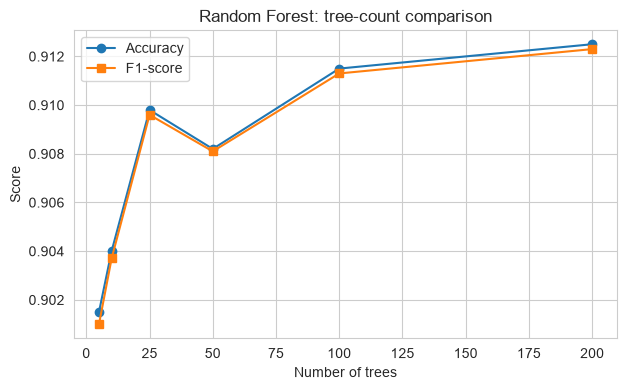

Best number of trees: 200


In [42]:
tree_counts = [5, 10, 25, 50, 100, 200]
rf_rows = []
for n in tree_counts:
    m = RandomForestClassifier(n_estimators=n, criterion="entropy", max_depth=12,
                               n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_r, ytr_c)
    p = m.predict(Xte_r)
    rf_rows.append({"n_estimators": n,
                    "Accuracy": accuracy_score(yte_c, p),
                    "Precision": precision_score(yte_c, p, average="weighted", zero_division=0),
                    "Recall": recall_score(yte_c, p, average="weighted", zero_division=0),
                    "F1-score": f1_score(yte_c, p, average="weighted", zero_division=0)})
    cls_preds[f"Random Forest ({n} trees)"] = p
rf_table = pd.DataFrame(rf_rows).round(4)
display(rf_table)

plt.figure(figsize=(7, 4))
plt.plot(rf_table["n_estimators"], rf_table["Accuracy"], marker="o", label="Accuracy")
plt.plot(rf_table["n_estimators"], rf_table["F1-score"], marker="s", label="F1-score")
plt.xlabel("Number of trees"); plt.ylabel("Score"); plt.title("Random Forest: tree-count comparison")
plt.legend(); plt.show()

best_n = int(rf_table.sort_values("F1-score", ascending=False).iloc[0]["n_estimators"])
print("Best number of trees:", best_n)

**Cell 17 – Final model-comparison table (all classifiers)**

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest (200 trees),0.9125,0.9123,0.9125,0.9123
1,Decision Tree (entropy),0.8982,0.8975,0.8982,0.8973
2,SVM linear,0.8352,0.8610,0.8352,0.8265
3,SVM rbf,0.7442,0.7487,0.7442,0.7434
4,Naive Bayes,0.7382,0.7840,0.7382,0.7249
5,SVM poly,0.6948,0.7112,0.6948,0.7010
6,KNN (k=5),0.5538,0.5584,0.5538,0.5555


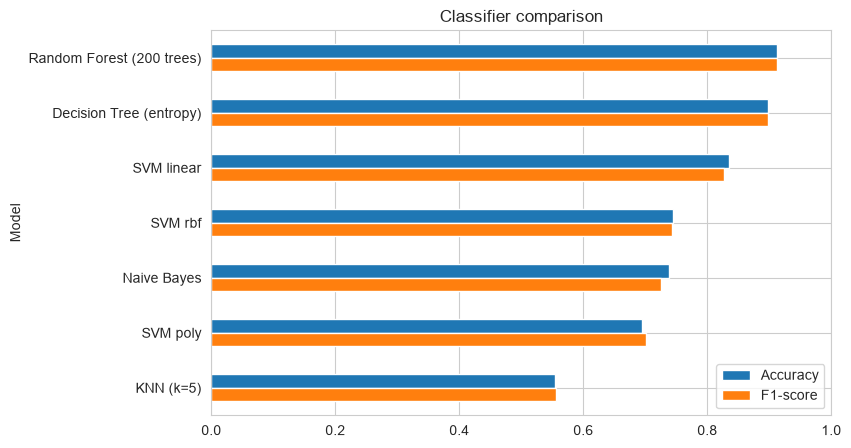

In [43]:
best_row = rf_table[rf_table["n_estimators"] == best_n].iloc[0]
cls_results.append({"Model": f"Random Forest ({best_n} trees)", "Accuracy": best_row["Accuracy"],
                    "Precision": best_row["Precision"], "Recall": best_row["Recall"],
                    "F1-score": best_row["F1-score"]})
comparison = pd.DataFrame(cls_results).sort_values("F1-score", ascending=False).reset_index(drop=True).round(4)
display(comparison)

comparison.set_index("Model")[["Accuracy", "F1-score"]].plot(kind="barh", figsize=(8, 5), title="Classifier comparison")
plt.gca().invert_yaxis(); plt.xlim(0, 1); plt.show()

**Cell 18 – Sample correct and incorrect predictions (best model)**

In [44]:
best_name = comparison.iloc[0]["Model"]
best_pred = cls_preds[best_name]
print("Best model:", best_name)

samples = test_df.iloc[te_pos][["date", "store_nbr", "family", "onpromotion", "sales"]].copy().reset_index(drop=True)
samples["actual_class"] = yte_c
samples["predicted_class"] = best_pred
samples["result"] = np.where(samples["actual_class"] == samples["predicted_class"], "CORRECT", "INCORRECT")

print("\nCorrect predictions:")
display(samples[samples["result"] == "CORRECT"].head(5))
print("Incorrect predictions:")
display(samples[samples["result"] == "INCORRECT"].head(5))

Best model: Random Forest (200 trees)

Correct predictions:


,date,store_nbr,family,onpromotion,sales,actual_class,predicted_class,result
0,2017-08-08,54,BABY CARE,0,0.0,Low,Low,CORRECT
1,2017-07-26,17,SEAFOOD,1,9.0,Medium,Medium,CORRECT
2,2017-07-09,17,GROCERY I,64,6137.0,High,High,CORRECT
3,2017-07-08,39,PERSONAL CARE,7,386.0,High,High,CORRECT
4,2017-08-08,53,GROCERY II,0,7.0,Medium,Medium,CORRECT


Incorrect predictions:


,date,store_nbr,family,onpromotion,sales,actual_class,predicted_class,result
13,2017-08-03,25,PLAYERS AND ELECTRONICS,0,9.0,Medium,Low,INCORRECT
24,2017-07-08,39,BEAUTY,3,5.0,Low,Medium,INCORRECT
34,2017-08-06,25,SEAFOOD,0,7.0,Medium,Low,INCORRECT
44,2017-08-11,20,CELEBRATION,0,5.0,Low,Medium,INCORRECT
69,2017-08-12,20,PLAYERS AND ELECTRONICS,0,6.0,Low,Medium,INCORRECT


## Task 7 – K-Means clustering (k = 2, 3, 4, 5)
Clustering uses the **full dataset**. Products (families) and stores are grouped by their behaviour.

**Cell 19 – Build aggregated tables**

In [45]:
def zero_share(s):
    return (s == 0).mean()

fam_agg = full.groupby("family").agg(avg_sales=("sales", "mean"), std_sales=("sales", "std"),
                                     avg_promo=("onpromotion", "mean"),
                                     zero_share=("sales", zero_share)).reset_index()
store_agg = full.groupby("store_nbr").agg(avg_sales=("sales", "mean"), std_sales=("sales", "std"),
                                          avg_promo=("onpromotion", "mean"),
                                          zero_share=("sales", zero_share)).reset_index()
print("Families:", fam_agg.shape, "| Stores:", store_agg.shape)
display(fam_agg.head())

Families: (33, 5) | Stores: (54, 5)


,family,avg_sales,std_sales,avg_promo,zero_share
0,AUTOMOTIVE,6.101236,6.191691,0.052597,0.127848
1,BABY CARE,0.110528,0.681064,0.000583,0.941310
2,BEAUTY,3.715723,4.794668,0.148269,0.262822
3,BEVERAGES,2385.793151,2307.882305,9.973586,0.080617
4,BOOKS,0.070797,0.547981,0.000000,0.969550


**Cell 20 – Cluster function: elbow plot, silhouette, cluster profiles**

In [46]:
def cluster_analysis(agg, id_col, title):
    feats = [c for c in agg.columns if c != id_col]
    Xc = StandardScaler().fit_transform(agg[feats])

    # elbow plot
    ks = range(2, 9)
    inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc).inertia_ for k in ks]
    plt.figure(figsize=(6, 4))
    plt.plot(list(ks), inertias, marker="o")
    plt.xlabel("k"); plt.ylabel("Inertia (WCSS)"); plt.title(f"Elbow plot – {title}")
    plt.show()

    # k = 2..5
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    out = {}
    for ax, k in zip(axes, [2, 3, 4, 5]):
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
        sil = silhouette_score(Xc, km.labels_)
        ax.scatter(coords[:, 0], coords[:, 1], c=km.labels_, cmap="viridis", s=40)
        ax.set_title(f"k={k} | silhouette={sil:.3f}")
        out[k] = (km.labels_, sil)
    plt.suptitle(f"K-Means groups of {title} (PCA view)")
    plt.tight_layout(); plt.show()

    print("Silhouette scores:", {k: round(v[1], 3) for k, v in out.items()})
    return feats, out

**Cell 21 – Cluster product families**

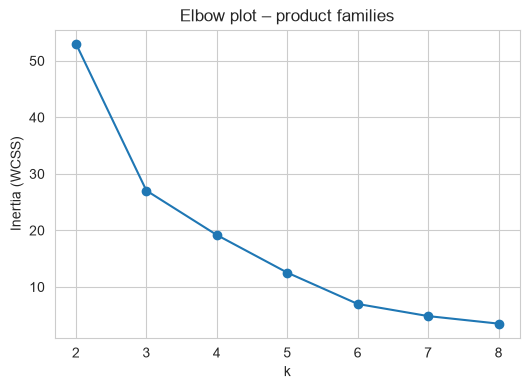

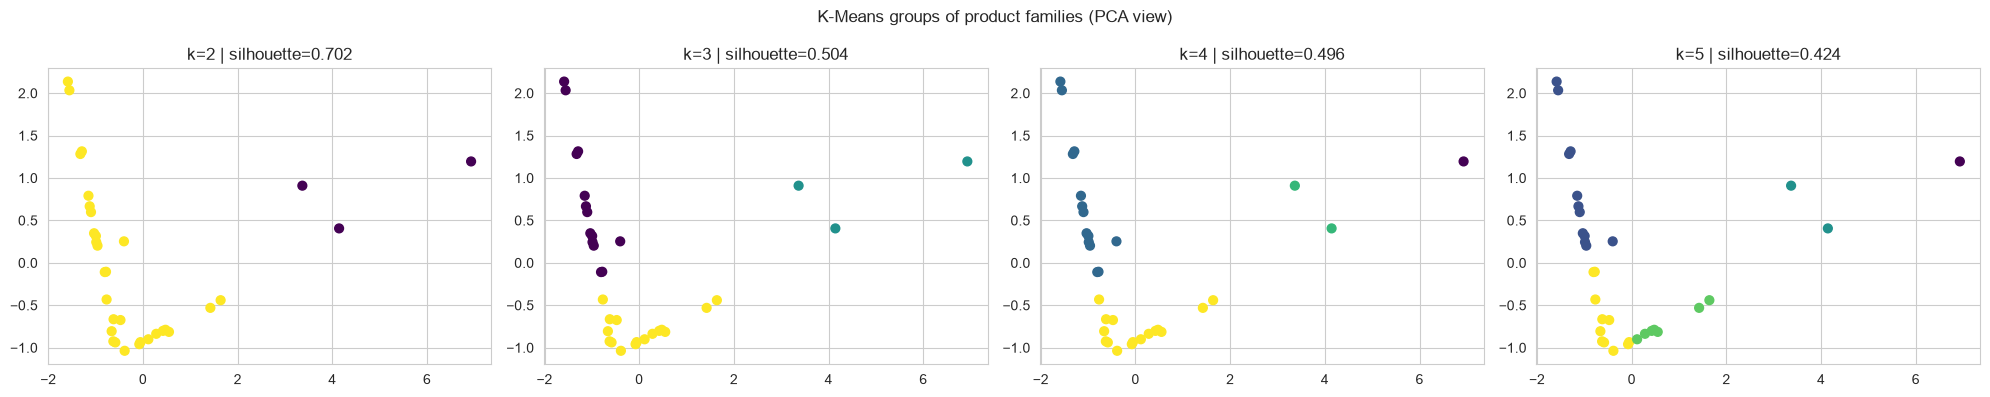

Silhouette scores: {2: 0.702, 3: 0.504, 4: 0.496, 5: 0.424}

Cluster profile for k=3:


,avg_sales,std_sales,avg_promo,zero_share,n_items
cluster,,,,,
0,18.05,26.37,0.25,0.57,14
1,2504.04,2456.19,14.44,0.15,3
2,252.61,241.90,2.44,0.12,16



Cluster profile for k=4:


,avg_sales,std_sales,avg_promo,zero_share,n_items
cluster,,,,,
0,3776.97,2874.21,21.06,0.08,1
1,18.05,26.37,0.25,0.57,14
2,1867.57,2247.18,11.13,0.18,2
3,252.61,241.90,2.44,0.12,16


,cluster,family,avg_sales
12,0,GROCERY I,3776.97
1,1,BABY CARE,0.11
6,1,CELEBRATION,8.37
4,1,BOOKS,0.07
14,1,HARDWARE,1.14
15,1,HOME AND KITCHEN I,20.47
17,1,HOME APPLIANCES,0.46
31,1,SCHOOL AND OFFICE SUPPLIES,2.96
27,1,PLAYERS AND ELECTRONICS,6.19
26,1,PET SUPPLIES,3.92


In [47]:
feats_f, out_f = cluster_analysis(fam_agg, "family", "product families")
for k in [3, 4]:
    prof = fam_agg.assign(cluster=out_f[k][0]).groupby("cluster")[feats_f].mean().round(2)
    prof["n_items"] = fam_agg.assign(cluster=out_f[k][0]).groupby("cluster").size()
    print(f"\nCluster profile for k={k}:")
    display(prof)
members = fam_agg.assign(cluster=out_f[4][0]).sort_values("cluster")[["cluster", "family", "avg_sales"]]
display(members.round(2))

**Cell 22 – Cluster stores**

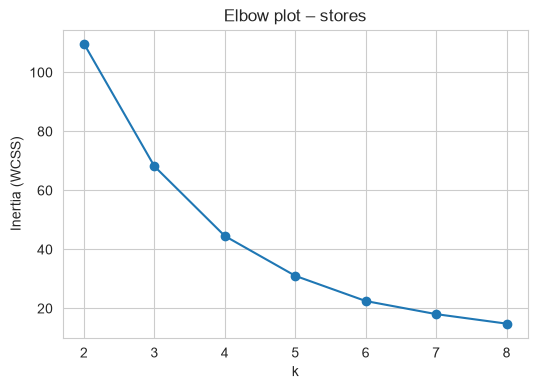

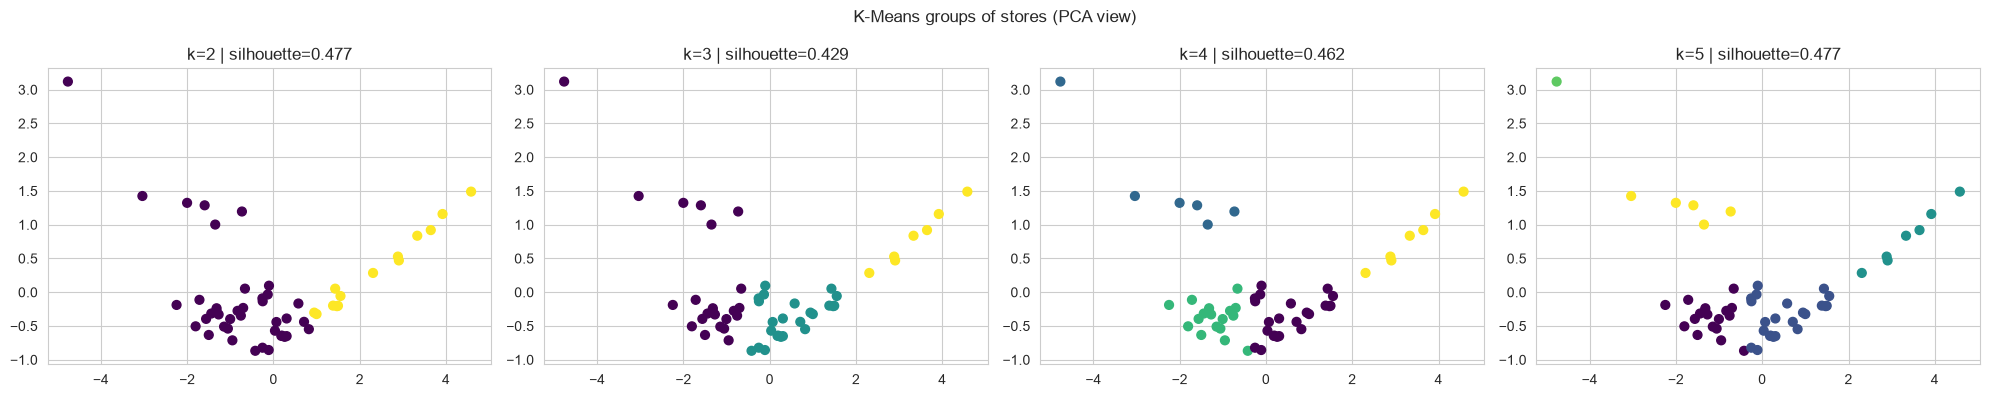

Silhouette scores: {2: 0.477, 3: 0.429, 4: 0.462, 5: 0.477}

Cluster profile for k=3:


,avg_sales,std_sales,avg_promo,zero_share,n_stores
cluster,,,,,
0,181.54,549.88,2.10,0.42,23
1,376.65,944.63,2.85,0.25,24
2,872.14,2127.64,3.38,0.19,7



Cluster profile for k=4:


,avg_sales,std_sales,avg_promo,zero_share,n_stores
cluster,,,,,
0,381.96,959.75,2.87,0.25,23
1,142.86,595.68,2.13,0.66,6
2,198.48,537.23,2.12,0.33,18
3,872.14,2127.64,3.38,0.19,7


In [48]:
feats_s, out_s = cluster_analysis(store_agg, "store_nbr", "stores")
for k in [3, 4]:
    prof = store_agg.assign(cluster=out_s[k][0]).groupby("cluster")[feats_s].mean().round(2)
    prof["n_stores"] = store_agg.assign(cluster=out_s[k][0]).groupby("cluster").size()
    print(f"\nCluster profile for k={k}:")
    display(prof)

## Task 8 – Inventory planning and limitations
**Cell 23 – Run this cell, then paste the printed text into a Markdown cell / your report**

In [49]:
summary = f"""
HOW THE ANALYSIS SUPPORTS INVENTORY PLANNING
- Regression (Random Forest) gives a unit-sales forecast per store and product family -> use it to set reorder quantities.
  Best regression: R2 = {reg_table['R2'].max():.3f}, lowest MAE = {reg_table['MAE'].min():.2f} units.
- Low/Medium/High classes ({best_name}, F1 = {comparison.iloc[0]['F1-score']:.3f}) let managers flag items likely to be
  fast-moving (stock more) or slow-moving (avoid overstock and expiry waste).
- K-Means groups of families/stores allow one stocking policy per group instead of 33 families x 54 stores separate rules.
- Promotions, weekends, paydays and holidays are explicit features -> demand peaks can be planned in advance.

LIMITATIONS
- No item price column exists; oil price was used only as an economic proxy, so price elasticity is not modelled.
- Models were trained on 12 stores and about 1 year for speed; results may differ for all stores.
- SVM/KNN/NB used sampled rows (8000 train / 4000 test), so scores are estimates.
- Lag features need recent sales history (7+ days); new items/stores (cold start) cannot be forecast this way.
- Class thresholds come from training percentiles; different thresholds change class balance and scores.
- Stock-outs and closed days (zero sales) look like low demand but may be missing supply, not low demand.
- Family-level sales are aggregated across many products, hiding item-level variation.
- A single chronological split was used; rolling-origin validation would be more robust.
"""
print(summary)


HOW THE ANALYSIS SUPPORTS INVENTORY PLANNING
- Regression (Random Forest) gives a unit-sales forecast per store and product family -> use it to set reorder quantities.
  Best regression: R2 = 0.937, lowest MAE = 60.26 units.
- Low/Medium/High classes (Random Forest (200 trees), F1 = 0.912) let managers flag items likely to be
  fast-moving (stock more) or slow-moving (avoid overstock and expiry waste).
- K-Means groups of families/stores allow one stocking policy per group instead of 33 families x 54 stores separate rules.
- Promotions, weekends, paydays and holidays are explicit features -> demand peaks can be planned in advance.

LIMITATIONS
- No item price column exists; oil price was used only as an economic proxy, so price elasticity is not modelled.
- Models were trained on 12 stores and about 1 year for speed; results may differ for all stores.
- SVM/KNN/NB used sampled rows (8000 train / 4000 test), so scores are estimates.
- Lag features need recent sales history (7+ days); n